# Embedding-dimension sweep: GUI screen prediction vs. projection size

Reads the output of `4_sweep_embedding_dimensions.py` from `dimension_sweep/` and presents it the way the other result notebooks do: one compact table and one paper-style figure per sweep configuration (protocol × projector hidden width), with the Screen2Vec Table 3 reference and a LaTeX fragment exported to `graphics/dimension_sweep/`.

Nothing is trained or evaluated here. Run the sweep first on a machine with the raw embeddings, for example

```bash
python 4_sweep_embedding_dimensions.py run --gpu 0                      # permissive recipe, seeds 42
python 4_sweep_embedding_dimensions.py run --protocol strict --dims 64,256,768
python 4_sweep_embedding_dimensions.py run --dims 128,768 --seeds 42,43,44   # error bars
```

then execute this notebook. Every `results*.json` under `dimension_sweep/` is picked up automatically. The intended pair of runs (`_run_dimension_sweep.ps1`) is the README recipe width, hidden 1024 over D = 16 … 1024, whose D = 768 point is the canonical run behind the numbers in `SUMMARY.md`, and the wide projector, hidden 4096 over D = 16 … 2048, which is the only way to reach D = 2048. Section 4 overlays the two so the effect of the hidden width is visible directly.

**Reading the numbers** (`REPLICATION_AUDIT.md` §2–3): **Top-1** and **MRR** are the informative columns. Top-0.1 % and above are saturated by the concatenated app-description half (an app-only oracle already reaches 0.9968 at Top-0.1 %), and normalised RMSE is not comparable to the paper's because the paper evaluates unnormalised vectors. The paper reference row is Screen2Vec-EUCLIDEAN-spatial, 768 learned + 768 app-description dimensions; every sweep point uses D learned + 768 app-description dimensions.

In [1]:
from pathlib import Path
import importlib
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "utils.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from the repository or a subdirectory.")
sys.path.insert(0, str(ROOT))
sweep = importlib.import_module("4_sweep_embedding_dimensions")

SWEEP_DIR = ROOT / "dimension_sweep"
PDF_DIR = ROOT / "graphics/dimension_sweep"
PDF_DIR.mkdir(parents=True, exist_ok=True)

FIGSIZE = (4.75, 2.75)          # inches, paper column; change only this for sizing
SHOW_SATURATED_PANEL = True     # second panel with the Top-k% columns
TABLE_METRICS = ["top1", "mrr", "top001pct", "top01pct", "top1pct", "nrmse"]
LABELS = dict(sweep.METRIC_LABELS)

# Paper reference: read from the evaluator when its dependencies are installed,
# otherwise fall back to the same numbers (Screen2Vec Table 3, EUCLIDEAN-spatial).
try:
    PAPER = importlib.import_module("4_evaluate_screen_prediction").PAPER_TABLE3["Screen2Vec-EUCLIDEAN-spatial"]
except Exception:
    PAPER = {"top1": 0.061, "top001pct": 0.258, "top01pct": 0.969, "top1pct": 0.998, "top5pct": 1.00, "nrmse": 0.853}

sns.set_theme(style="whitegrid", context="paper")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 150, "pdf.fonttype": 42, "ps.fonttype": 42,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 180)

## 1. Load every sweep configuration

One results file per protocol and hidden width, e.g. `results.json` (permissive, hidden 1024), `results_strict.json`, `results_h4096.json`. Each holds one entry per (dimension, seed).

In [2]:
result_files = sorted(p for p in SWEEP_DIR.glob("results*.json") if p.is_file())
if not result_files:
    raise FileNotFoundError(f"No results*.json under {SWEEP_DIR}; run 4_sweep_embedding_dimensions.py first.")

configs = {}
for path in result_files:
    data = json.loads(path.read_text(encoding="utf-8"))
    rows = []
    for dim_key, by_seed in data.get("runs", {}).items():
        for seed_key, m in by_seed.items():
            row = {"proj_dim": int(dim_key), "seed": int(seed_key)}
            row.update({k: m.get(k, np.nan) for k in sweep.METRIC_KEYS})
            row.update({k: m.get(k) for k in sweep.POPULATION_KEYS})
            row["completed_at"] = m.get("completed_at")
            rows.append(row)
    if not rows:
        continue
    name = path.stem.removeprefix("results").lstrip("_") or "permissive"
    configs[name] = {"meta": data.get("meta", {}), "runs": pd.DataFrame(rows).sort_values(["proj_dim", "seed"])}

overview = pd.DataFrame([{
    "config": name,
    "protocol": c["meta"].get("protocol"),
    "hidden_dim": c["meta"].get("hidden_dim"),
    "dims": ", ".join(str(d) for d in sorted(c["runs"]["proj_dim"].unique())),
    "seeds": ", ".join(str(s) for s in sorted(c["runs"]["seed"].unique())),
    "runs": len(c["runs"]),
    "git": c["meta"].get("git_revision"),
    "trace index coverage": (c["meta"].get("trace_index_meta") or {}).get("coverage"),
} for name, c in configs.items()])
display(overview.style.format({"trace index coverage": "{:.4f}"}, na_rep="–").hide(axis="index"))

config,protocol,hidden_dim,dims,seeds,runs,git,trace index coverage
permissive,permissive,1024,"16, 32, 64, 128, 256, 512, 768, 1024","42, 43, 44",24,c5e4006,0.9984
h4096,permissive,4096,"16, 32, 64, 128, 256, 512, 768, 1024, 2048","42, 43, 44",27,c5e4006,0.9984


## 2. Summary per configuration

Mean over seeds (± sample standard deviation when a dimension was repeated). The last column gives the Top-1 gain over the paper row; the smallest dimension whose mean Top-1 beats the paper is marked. Full-precision values are exported as CSV, the compact table as a LaTeX fragment.

In [3]:
def summarise(runs):
    g = runs.groupby("proj_dim")
    out = pd.DataFrame({"n": g["seed"].size()})
    for k in TABLE_METRICS:
        out[f"{k}_mean"] = g[k].mean()
        out[f"{k}_std"] = g[k].std(ddof=1).fillna(0.0)
    out["top1_delta_vs_paper"] = out["top1_mean"] - PAPER["top1"]
    out["beats_paper_top1"] = out["top1_mean"] > PAPER["top1"]
    return out.reset_index()


def compact(summary):
    rows = []
    for r in summary.itertuples(index=False):
        row = {"D": int(r.proj_dim), "n": int(r.n)}
        for k in TABLE_METRICS:
            mean, std = getattr(r, f"{k}_mean"), getattr(r, f"{k}_std")
            row[LABELS[k]] = f"{mean:.4f} ± {std:.4f}" if r.n > 1 else f"{mean:.4f}"
        row["Δ Top-1 vs paper"] = f"{r.top1_delta_vs_paper:+.4f}"
        rows.append(row)
    ref = {"D": "768 (paper)", "n": ""}
    ref.update({LABELS[k]: (f"{PAPER[k]:.4f}" if k in PAPER else "–") for k in TABLE_METRICS})
    ref["Δ Top-1 vs paper"] = ""
    rows.append(ref)
    return pd.DataFrame(rows)


def latex_fragment(summary, name):
    cols = " & ".join(LABELS[k] for k in TABLE_METRICS)
    lines = [
        r"\begin{table}[t]", r"    \centering",
        rf"    \caption{{GUI screen prediction against the learned screen-embedding dimension $D$ "
        rf"(sweep configuration \texttt{{{name}}}; every point uses $D$ + 768 app-description dimensions). "
        r"Mean over seeds, $\pm$ sample SD where repeated. Top-1 and MRR are the informative columns; "
        r"Top-0.1\,\% and above are saturated by app identity and normalised RMSE is not comparable to the paper's.}",
        rf"    \label{{tab:dimension_sweep_{name}}}", r"    \small",
        rf"    \begin{{tabular}}{{@{{}}rr{'r' * len(TABLE_METRICS)}@{{}}}}", r"        \toprule",
        rf"        $D$ & $n$ & {cols} \\", r"        \midrule",
    ]
    for r in summary.itertuples(index=False):
        cells = []
        for k in TABLE_METRICS:
            mean, std = getattr(r, f"{k}_mean"), getattr(r, f"{k}_std")
            cells.append(f"{mean:.4f} $\\pm$ {std:.4f}" if r.n > 1 else f"{mean:.4f}")
        lines.append(f"        {int(r.proj_dim)} & {int(r.n)} & " + " & ".join(cells) + r" \\")
    lines += [r"        \midrule",
              "        768 (paper) & -- & " + " & ".join(f"{PAPER[k]:.4f}" if k in PAPER else "--" for k in TABLE_METRICS) + r" \\",
              r"        \bottomrule", r"    \end{tabular}", r"\end{table}"]
    return "\n".join(lines)


summaries = {}
for name, c in configs.items():
    summary = summarise(c["runs"])
    summaries[name] = summary
    summary.to_csv(PDF_DIR / f"dimension_sweep_{name}.csv", index=False)
    (PDF_DIR / f"dimension_sweep_{name}.tex").write_text(latex_fragment(summary, name) + "\n", encoding="utf-8")
    winners = summary.loc[summary["beats_paper_top1"], "proj_dim"]
    note = (f"smallest D beating the paper's Top-1 ({PAPER['top1']:.4f}): **{int(winners.min())}**"
            if len(winners) else f"no dimension beats the paper's Top-1 ({PAPER['top1']:.4f})")
    display(Markdown(f"### `{name}` — protocol {c['meta'].get('protocol')}, hidden {c['meta'].get('hidden_dim')} · {note}"))
    display(compact(summary).style.hide(axis="index"))

### `permissive` — protocol permissive, hidden 1024 · smallest D beating the paper's Top-1 (0.0610): **16**

D,n,Top-1,MRR,Top-0.01%,Top-0.1%,Top-1%,Norm.RMSE,Δ Top-1 vs paper
16,3,0.1015 ± 0.0029,0.2833 ± 0.0025,0.6356 ± 0.0018,0.9781 ± 0.0014,0.9928 ± 0.0010,0.4685 ± 0.0214,+0.0405
32,3,0.1126 ± 0.0069,0.2928 ± 0.0053,0.6431 ± 0.0011,0.9842 ± 0.0012,0.9966 ± 0.0007,0.5508 ± 0.0225,+0.0516
64,3,0.1128 ± 0.0242,0.2954 ± 0.0176,0.6518 ± 0.0009,0.9865 ± 0.0020,0.9976 ± 0.0010,0.5685 ± 0.0448,+0.0518
128,3,0.1023 ± 0.0246,0.2895 ± 0.0179,0.6568 ± 0.0010,0.9882 ± 0.0012,0.9981 ± 0.0006,0.5806 ± 0.0584,+0.0413
256,3,0.0922 ± 0.0294,0.2818 ± 0.0212,0.6558 ± 0.0029,0.9898 ± 0.0006,0.9983 ± 0.0006,0.5566 ± 0.0640,+0.0312
512,3,0.0951 ± 0.0106,0.2828 ± 0.0070,0.6514 ± 0.0021,0.9883 ± 0.0014,0.9981 ± 0.0004,0.5898 ± 0.0284,+0.0341
768,3,0.0900 ± 0.0061,0.2788 ± 0.0037,0.6507 ± 0.0013,0.9886 ± 0.0013,0.9982 ± 0.0004,0.5852 ± 0.0135,+0.0290
1024,3,0.1140 ± 0.0135,0.2953 ± 0.0100,0.6471 ± 0.0013,0.9885 ± 0.0009,0.9986 ± 0.0002,0.6252 ± 0.0079,+0.0530
768 (paper),,0.0610,–,0.2580,0.9690,0.9980,0.8530,


### `h4096` — protocol permissive, hidden 4096 · smallest D beating the paper's Top-1 (0.0610): **16**

D,n,Top-1,MRR,Top-0.01%,Top-0.1%,Top-1%,Norm.RMSE,Δ Top-1 vs paper
16,3,0.0996 ± 0.0039,0.2832 ± 0.0035,0.6395 ± 0.0033,0.9784 ± 0.0023,0.9925 ± 0.0014,0.4411 ± 0.0148,+0.0386
32,3,0.1006 ± 0.0037,0.2857 ± 0.0016,0.6484 ± 0.0053,0.9825 ± 0.0009,0.9954 ± 0.0004,0.4953 ± 0.0232,+0.0396
64,3,0.0977 ± 0.0066,0.2830 ± 0.0052,0.6466 ± 0.0034,0.9843 ± 0.0011,0.9964 ± 0.0004,0.5116 ± 0.0145,+0.0367
128,3,0.0795 ± 0.0107,0.2698 ± 0.0088,0.6483 ± 0.0016,0.9858 ± 0.0009,0.9967 ± 0.0004,0.4570 ± 0.0226,+0.0185
256,3,0.0874 ± 0.0069,0.2761 ± 0.0052,0.6481 ± 0.0040,0.9847 ± 0.0016,0.9961 ± 0.0004,0.4688 ± 0.0231,+0.0264
512,3,0.0820 ± 0.0070,0.2730 ± 0.0062,0.6500 ± 0.0035,0.9831 ± 0.0013,0.9955 ± 0.0006,0.4635 ± 0.0126,+0.0210
768,3,0.0918 ± 0.0088,0.2797 ± 0.0064,0.6475 ± 0.0026,0.9828 ± 0.0009,0.9953 ± 0.0003,0.4880 ± 0.0276,+0.0308
1024,3,0.0947 ± 0.0194,0.2828 ± 0.0147,0.6474 ± 0.0018,0.9835 ± 0.0005,0.9962 ± 0.0007,0.5031 ± 0.0499,+0.0337
2048,3,0.0905 ± 0.0042,0.2779 ± 0.0038,0.6410 ± 0.0044,0.9842 ± 0.0008,0.9962 ± 0.0004,0.5182 ± 0.0088,+0.0295
768 (paper),,0.0610,–,0.2580,0.9690,0.9980,0.8530,


## 3. Curves

Left: Top-1 and MRR against $D$ on a log₂ axis, dashed line = paper Top-1, error bars = sample SD over seeds where repeated. Right (optional): the Top-k % columns, shown only to document their saturation. One PDF per configuration goes to `graphics/dimension_sweep/`.

**`permissive`** — protocol permissive, hidden 1024

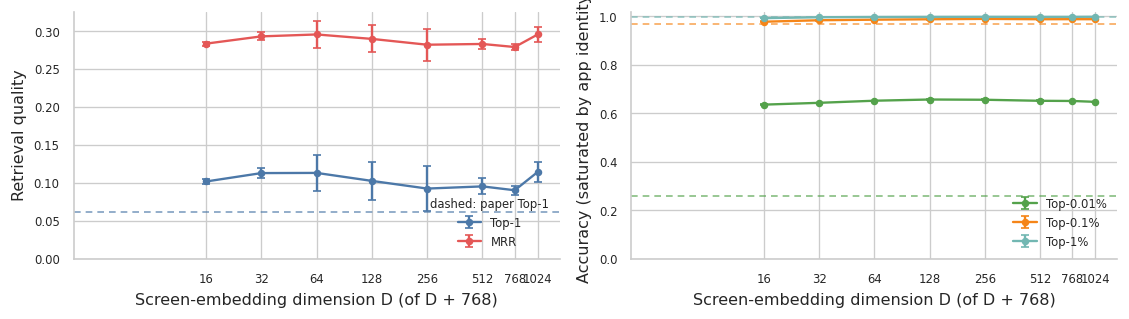

**`h4096`** — protocol permissive, hidden 4096

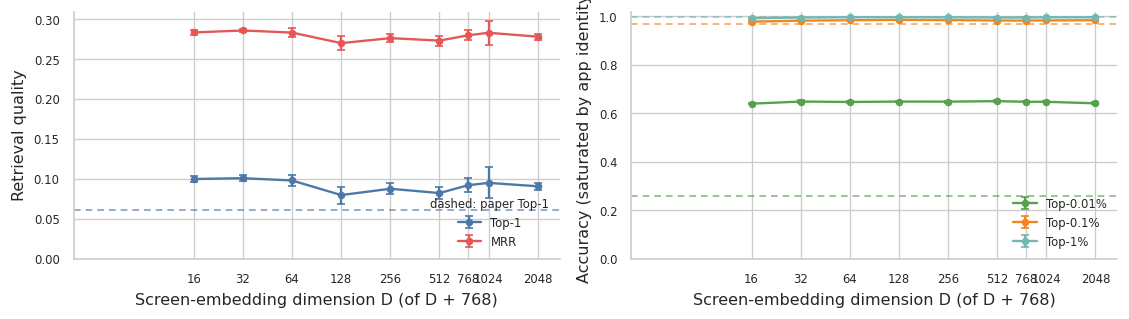

In [4]:
def plot_config(name, summary, meta):
    dims = summary["proj_dim"].to_numpy()
    multi = (summary["n"] > 1).any()
    n_panels = 2 if SHOW_SATURATED_PANEL else 1
    fig, axes = plt.subplots(1, n_panels, figsize=(FIGSIZE[0] * n_panels, FIGSIZE[1]), squeeze=False)
    axes = axes[0]

    def curve(ax, key, color, label):
        ax.errorbar(dims, summary[f"{key}_mean"], yerr=summary[f"{key}_std"] if multi else None,
                    color=color, marker="o", markersize=3.5, linewidth=1.4, capsize=2.5, label=label)
        if key in PAPER:
            ax.axhline(PAPER[key], color=color, linestyle=(0, (4, 3)), linewidth=1, alpha=0.7)

    for ax in axes:
        ax.set_xscale("log", base=2)
        ax.set_xticks(dims)
        ax.set_xticklabels([str(d) for d in dims], fontsize=7)
        ax.minorticks_off()
        ax.set_xlabel("Screen-embedding dimension D (of D + 768)")
        ax.tick_params(labelsize=7)

    curve(axes[0], "top1", "#4C78A8", "Top-1")
    curve(axes[0], "mrr", "#E45756", "MRR")
    axes[0].set_ylim(0, None)
    axes[0].set_ylabel("Retrieval quality")
    axes[0].legend(frameon=False, fontsize=7, loc="lower right", title="dashed: paper Top-1", title_fontsize=7)

    if SHOW_SATURATED_PANEL:
        curve(axes[1], "top001pct", "#54A24B", "Top-0.01%")
        curve(axes[1], "top01pct", "#F58518", "Top-0.1%")
        curve(axes[1], "top1pct", "#72B7B2", "Top-1%")
        axes[1].set_ylim(0, 1.02)
        axes[1].set_ylabel("Accuracy (saturated by app identity)")
        axes[1].legend(frameon=False, fontsize=7, loc="lower right")

    fig.tight_layout()
    fig.savefig(PDF_DIR / f"dimension_sweep_{name}.pdf", bbox_inches="tight")
    fig.savefig(PDF_DIR / f"dimension_sweep_{name}.png", bbox_inches="tight")
    display(Markdown(f"**`{name}`** — protocol {meta.get('protocol')}, hidden {meta.get('hidden_dim')}"))
    plt.show()


for name, summary in summaries.items():
    plot_config(name, summary, configs[name]["meta"])

## 4. Hidden-width comparison

For every protocol that was swept with more than one projector hidden width, the curves are overlaid (solid = recipe width 1024, dashed = other widths) and the per-dimension differences are tabulated. The hidden layer is internal to the projector and never part of the stored D-dimensional embedding, but it changes the projector's capacity (about 5 M parameters at 1024 versus 20 M at 4096 for D = 768). Overlapping curves mean the width does not matter and the 2048 point of the wide sweep can be read together with the recipe curve; diverging curves mean projector capacity is a factor and every number must be reported with its width.

### protocol `permissive` — hidden widths 1024, 4096

D,n (h1024),Top-1 (h1024),Top-1 SD (h1024),MRR (h1024),MRR SD (h1024),n (h4096),Top-1 (h4096),Top-1 SD (h4096),MRR (h4096),MRR SD (h4096),Δ Top-1 (h4096 − h1024),Δ MRR (h4096 − h1024)
16,3.000000,0.1015,0.0029,0.2833,0.0025,3,0.0996,0.0039,0.2832,0.0035,-0.0019,-0.0000
32,3.000000,0.1126,0.0069,0.2928,0.0053,3,0.1006,0.0037,0.2857,0.0016,-0.0120,-0.0072
64,3.000000,0.1128,0.0242,0.2954,0.0176,3,0.0977,0.0066,0.2830,0.0052,-0.0151,-0.0123
128,3.000000,0.1023,0.0246,0.2895,0.0179,3,0.0795,0.0107,0.2698,0.0088,-0.0228,-0.0197
256,3.000000,0.0922,0.0294,0.2818,0.0212,3,0.0874,0.0069,0.2761,0.0052,-0.0048,-0.0057
512,3.000000,0.0951,0.0106,0.2828,0.0070,3,0.0820,0.0070,0.2730,0.0062,-0.0131,-0.0099
768,3.000000,0.0900,0.0061,0.2788,0.0037,3,0.0918,0.0088,0.2797,0.0064,+0.0019,+0.0009
1024,3.000000,0.1140,0.0135,0.2953,0.0100,3,0.0947,0.0194,0.2828,0.0147,-0.0193,-0.0125
2048,–,–,–,–,–,3,0.0905,0.0042,0.2779,0.0038,–,–


largest |Δ Top-1| on the 8 shared dimensions: 0.0228


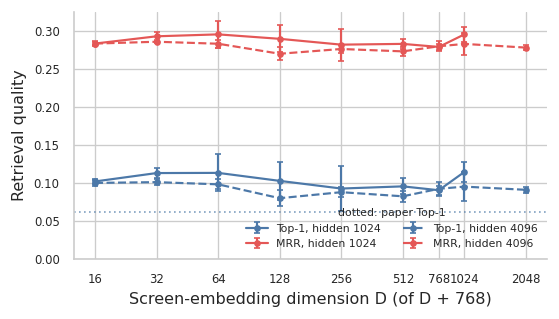

In [5]:
by_protocol = {}
for name, c in configs.items():
    by_protocol.setdefault(str(c["meta"].get("protocol")), []).append(name)

compared = False
for protocol, names in sorted(by_protocol.items()):
    if len(names) < 2:
        continue
    compared = True
    names = sorted(names, key=lambda n: int(configs[n]["meta"].get("hidden_dim") or 0))
    widths = {n: int(configs[n]["meta"].get("hidden_dim") or 0) for n in names}
    display(Markdown(f"### protocol `{protocol}` — hidden widths {', '.join(str(widths[n]) for n in names)}"))

    # Side-by-side table on the shared dimensions, differences relative to the narrowest width.
    base = names[0]
    merged = None
    for n in names:
        part = summaries[n][["proj_dim", "n", "top1_mean", "top1_std", "mrr_mean", "mrr_std"]].copy()
        part.columns = ["D", f"n (h{widths[n]})", f"Top-1 (h{widths[n]})", f"Top-1 SD (h{widths[n]})",
                        f"MRR (h{widths[n]})", f"MRR SD (h{widths[n]})"]
        merged = part if merged is None else merged.merge(part, on="D", how="outer")
    for n in names[1:]:
        merged[f"Δ Top-1 (h{widths[n]} − h{widths[base]})"] = merged[f"Top-1 (h{widths[n]})"] - merged[f"Top-1 (h{widths[base]})"]
        merged[f"Δ MRR (h{widths[n]} − h{widths[base]})"] = merged[f"MRR (h{widths[n]})"] - merged[f"MRR (h{widths[base]})"]
    merged = merged.sort_values("D")
    merged.to_csv(PDF_DIR / f"dimension_sweep_hidden_comparison_{protocol}.csv", index=False)
    fmt = {c: "{:+.4f}" if c.startswith("Δ") else "{:.4f}" for c in merged.columns if c != "D" and not c.startswith("n (")}
    display(merged.style.format(fmt, na_rep="–").hide(axis="index"))
    shared = merged.dropna(subset=[f"Top-1 (h{widths[n]})" for n in names])
    if len(shared):
        gaps = [shared[f"Δ Top-1 (h{widths[n]} − h{widths[base]})"].abs().max() for n in names[1:]]
        print(f"largest |Δ Top-1| on the {len(shared)} shared dimensions: {max(gaps):.4f}")

    # Overlay figure: Top-1 and MRR, one line style per width.
    styles = ["-", "--", ":", "-."]
    fig, ax = plt.subplots(figsize=FIGSIZE)
    for style, n in zip(styles, names):
        summary = summaries[n]
        multi = (summary["n"] > 1).any()
        for key, color, label in (("top1", "#4C78A8", "Top-1"), ("mrr", "#E45756", "MRR")):
            ax.errorbar(summary["proj_dim"], summary[f"{key}_mean"],
                        yerr=summary[f"{key}_std"] if multi else None, color=color, linestyle=style,
                        marker="o", markersize=3, linewidth=1.3, capsize=2, label=f"{label}, hidden {widths[n]}")
    ax.axhline(PAPER["top1"], color="#4C78A8", linestyle=(0, (1, 2)), linewidth=1, alpha=0.7)
    all_dims = sorted({int(d) for n in names for d in summaries[n]["proj_dim"]})
    ax.set_xscale("log", base=2)
    ax.set_xticks(all_dims)
    ax.set_xticklabels([str(d) for d in all_dims], fontsize=7)
    ax.minorticks_off()
    ax.set_ylim(0, None)
    ax.set_xlabel("Screen-embedding dimension D (of D + 768)")
    ax.set_ylabel("Retrieval quality")
    ax.tick_params(labelsize=7)
    ax.legend(frameon=False, fontsize=6.5, loc="lower right", ncol=2, title="dotted: paper Top-1", title_fontsize=6.5)
    fig.tight_layout()
    fig.savefig(PDF_DIR / f"dimension_sweep_hidden_comparison_{protocol}.pdf", bbox_inches="tight")
    fig.savefig(PDF_DIR / f"dimension_sweep_hidden_comparison_{protocol}.png", bbox_inches="tight")
    plt.show()

if not compared:
    print("Only one hidden width per protocol so far; run the second configuration to compare "
          "(see _run_dimension_sweep.ps1).")

## 5. Individual runs and provenance

Every (dimension, seed) run with its evaluated population, so a suspicious point can be traced to its log in `dimension_sweep/logs/`.

In [6]:
for name, c in configs.items():
    display(Markdown(f"**`{name}`**"))
    cols = ["proj_dim", "seed", "top1", "mrr", "top001pct", "top01pct", "top1pct", "top5pct", "nrmse",
            "n_traces", "n_screens_in_traces", "n_instances", "completed_at"]
    display(c["runs"][cols].style.format({k: "{:.4f}" for k in sweep.METRIC_KEYS}, na_rep="–").hide(axis="index"))
    meta = {k: v for k, v in c["meta"].items() if k != "trace_index_meta"}
    meta["trace_index_coverage"] = (c["meta"].get("trace_index_meta") or {}).get("coverage")
    print(json.dumps(meta, indent=2))

print("\nfiles in", PDF_DIR.relative_to(ROOT))
for path in sorted(PDF_DIR.iterdir()):
    print(f"  {path.name:45s} {path.stat().st_size / 1024:8.1f} KB")

**`permissive`**

proj_dim,seed,top1,mrr,top001pct,top01pct,top1pct,top5pct,nrmse,n_traces,n_screens_in_traces,n_instances,completed_at
16,42,0.1044,0.2855,0.6354,0.9796,0.9938,0.9983,0.4827,7164,61681,54517,2026-09-17T21:52:24
16,43,0.1015,0.2838,0.6375,0.9779,0.9929,0.9979,0.4789,7164,61681,54517,2026-09-18T18:42:49
16,44,0.0987,0.2805,0.6339,0.9768,0.9918,0.9973,0.4438,7164,61681,54517,2026-09-18T19:21:12
32,42,0.1191,0.2985,0.6437,0.9855,0.9973,0.9995,0.5766,7164,61681,54517,2026-09-17T22:31:27
32,43,0.1053,0.2879,0.6437,0.9838,0.9960,0.9992,0.5405,7164,61681,54517,2026-09-18T20:00:04
32,44,0.1134,0.2921,0.6418,0.9833,0.9964,0.9993,0.5353,7164,61681,54517,2026-09-18T20:38:50
64,42,0.1284,0.3073,0.6528,0.9884,0.9984,0.9999,0.5963,7164,61681,54517,2026-09-17T23:11:08
64,43,0.1252,0.3036,0.6511,0.9868,0.9980,0.9998,0.5925,7164,61681,54517,2026-09-18T21:18:36
64,44,0.0849,0.2752,0.6514,0.9844,0.9965,0.9994,0.5168,7164,61681,54517,2026-09-18T21:56:33
128,42,0.0949,0.2837,0.6559,0.9868,0.9976,0.9998,0.5768,7164,61681,54517,2026-09-17T23:50:49


{
  "recipe": "9_train_joint.py -> 6_generate_app_context_embeddings.py -> 4_evaluate_screen_prediction.py",
  "protocol": "permissive",
  "hidden_dim": 1024,
  "raw_embeddings_dir": "embeddings_4096_last",
  "trace_index": "trace_layout_index.csv",
  "seeds": [
    42,
    43,
    44
  ],
  "git_revision": "c5e4006",
  "sample_fraction": null,
  "updated_at": "2026-09-18T18:04:13",
  "trace_index_coverage": 0.9984304492838925
}


**`h4096`**

proj_dim,seed,top1,mrr,top001pct,top01pct,top1pct,top5pct,nrmse,n_traces,n_screens_in_traces,n_instances,completed_at
16,42,0.1041,0.2873,0.6424,0.9775,0.9922,0.9976,0.4519,7164,61681,54517,2026-09-17T21:52:41
16,43,0.0978,0.2811,0.6359,0.9810,0.9940,0.9980,0.4243,7164,61681,54517,2026-09-18T18:42:06
16,44,0.0969,0.2813,0.6402,0.9766,0.9912,0.9969,0.4472,7164,61681,54517,2026-09-18T19:20:39
32,42,0.1003,0.2853,0.6455,0.9823,0.9957,0.9991,0.4964,7164,61681,54517,2026-09-17T22:32:52
32,43,0.0971,0.2843,0.6545,0.9835,0.9950,0.9988,0.4715,7164,61681,54517,2026-09-18T20:00:05
32,44,0.1045,0.2874,0.6451,0.9818,0.9954,0.9990,0.5179,7164,61681,54517,2026-09-18T20:39:04
64,42,0.1052,0.2887,0.6473,0.9850,0.9969,0.9995,0.5282,7164,61681,54517,2026-09-17T23:12:37
64,43,0.0951,0.2818,0.6497,0.9848,0.9961,0.9991,0.5015,7164,61681,54517,2026-09-18T21:17:25
64,44,0.0929,0.2786,0.6429,0.9830,0.9962,0.9994,0.5050,7164,61681,54517,2026-09-18T21:57:28
128,42,0.0747,0.2663,0.6489,0.9862,0.9970,0.9994,0.4474,7164,61681,54517,2026-09-17T23:52:12


{
  "recipe": "9_train_joint.py -> 6_generate_app_context_embeddings.py -> 4_evaluate_screen_prediction.py",
  "protocol": "permissive",
  "hidden_dim": 4096,
  "raw_embeddings_dir": "embeddings_4096_last",
  "trace_index": "trace_layout_index.csv",
  "seeds": [
    42,
    43,
    44
  ],
  "git_revision": "c5e4006",
  "sample_fraction": null,
  "updated_at": "2026-09-18T18:04:13",
  "trace_index_coverage": 0.9984304492838925
}

files in graphics/dimension_sweep
  dimension_sweep_h4096.csv                          2.5 KB
  dimension_sweep_h4096.pdf                         20.8 KB
  dimension_sweep_h4096.png                         62.6 KB
  dimension_sweep_h4096.tex                          2.1 KB
  dimension_sweep_hidden_comparison_permissive.csv      1.9 KB
  dimension_sweep_hidden_comparison_permissive.pdf     18.3 KB
  dimension_sweep_hidden_comparison_permissive.png     48.0 KB
  dimension_sweep_permissive.csv                     2.2 KB
  dimension_sweep_permissive.pdf           